# Predicción de compra en sesiones de e-commerce · CRISP-ML(Q)

## Fase 1 · Business & Data Understanding

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json, os

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (make_scorer, fbeta_score, recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)
from xgboost import XGBClassifier
import joblib

RANDOM_STATE = 42
os.makedirs('../docs/capturas', exist_ok=True)
sns.set_theme(style='whitegrid')

### Carga de datos

In [2]:
df = pd.read_csv('../data/online_shoppers_intention.csv')
print(df.shape)
df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### Nombres de variables en español

In [3]:
nombres = {
    'Administrative': 'paginas_administrativas', 'Administrative_Duration': 'tiempo_administrativas',
    'Informational': 'paginas_informativas', 'Informational_Duration': 'tiempo_informativas',
    'ProductRelated': 'paginas_producto', 'ProductRelated_Duration': 'tiempo_producto',
    'BounceRates': 'tasa_rebote', 'ExitRates': 'tasa_salida', 'PageValues': 'valor_pagina',
    'SpecialDay': 'dia_especial', 'Month': 'mes', 'OperatingSystems': 'sistema_operativo',
    'Browser': 'navegador', 'Region': 'region', 'TrafficType': 'tipo_trafico',
    'VisitorType': 'tipo_visitante', 'Weekend': 'fin_de_semana', 'Revenue': 'compra'
}
meses = {'Jan': 'Ene', 'Apr': 'Abr', 'June': 'Jun', 'Aug': 'Ago', 'Dec': 'Dic'}
visitantes = {'Returning_Visitor': 'Recurrente', 'New_Visitor': 'Nuevo', 'Other': 'Otro'}

df = df.rename(columns=nombres)
df['mes'] = df['mes'].replace(meses)
df['tipo_visitante'] = df['tipo_visitante'].replace(visitantes)
df.head()

,paginas_administrativas,tiempo_administrativas,paginas_informativas,tiempo_informativas,paginas_producto,tiempo_producto,tasa_rebote,tasa_salida,valor_pagina,dia_especial,mes,sistema_operativo,navegador,region,tipo_trafico,tipo_visitante,fin_de_semana,compra
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Recurrente,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Recurrente,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Recurrente,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Recurrente,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Recurrente,True,False


### Exploración

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   paginas_administrativas  12330 non-null  int64  
 1   tiempo_administrativas   12330 non-null  float64
 2   paginas_informativas     12330 non-null  int64  
 3   tiempo_informativas      12330 non-null  float64
 4   paginas_producto         12330 non-null  int64  
 5   tiempo_producto          12330 non-null  float64
 6   tasa_rebote              12330 non-null  float64
 7   tasa_salida              12330 non-null  float64
 8   valor_pagina             12330 non-null  float64
 9   dia_especial             12330 non-null  float64
 10  mes                      12330 non-null  str    
 11  sistema_operativo        12330 non-null  int64  
 12  navegador                12330 non-null  int64  
 13  region                   12330 non-null  int64  
 14  tipo_trafico             12330 no

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
paginas_administrativas,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
tiempo_administrativas,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
paginas_informativas,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
tiempo_informativas,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
paginas_producto,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
tiempo_producto,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
tasa_rebote,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
tasa_salida,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
valor_pagina,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
dia_especial,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [6]:
print('Valores nulos por columna:')
print(df.isnull().sum().sum(), 'nulos en total')
print('Filas duplicadas:', df.duplicated().sum())

Valores nulos por columna:
0 nulos en total
Filas duplicadas: 125


### Balance de clases

compra
False    10422
True      1908
Name: count, dtype: int64
compra
False    0.845
True     0.155
Name: proportion, dtype: float64


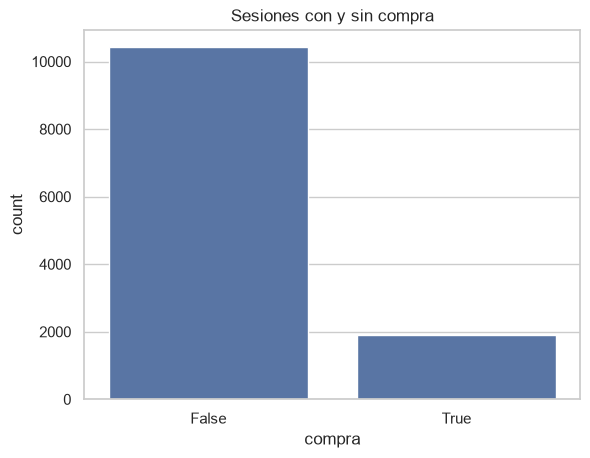

In [7]:
print(df['compra'].value_counts())
print(df['compra'].value_counts(normalize=True).round(3))

sns.countplot(x='compra', data=df)
plt.title('Sesiones con y sin compra')
plt.savefig('../docs/capturas/01_balance_clases.png', dpi=120, bbox_inches='tight')
plt.show()

### valor_pagina y tasa_salida según la compra

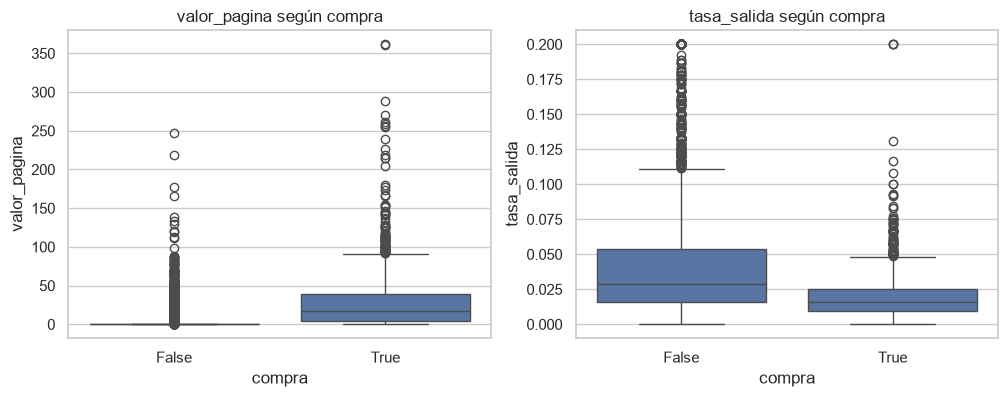

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x='compra', y='valor_pagina', data=df, ax=axes[0])
axes[0].set_title('valor_pagina según compra')
sns.boxplot(x='compra', y='tasa_salida', data=df, ax=axes[1])
axes[1].set_title('tasa_salida según compra')
plt.savefig('../docs/capturas/02_pagevalues_exitrates.png', dpi=120, bbox_inches='tight')
plt.show()

### Tasa de compra por mes y tipo de visitante

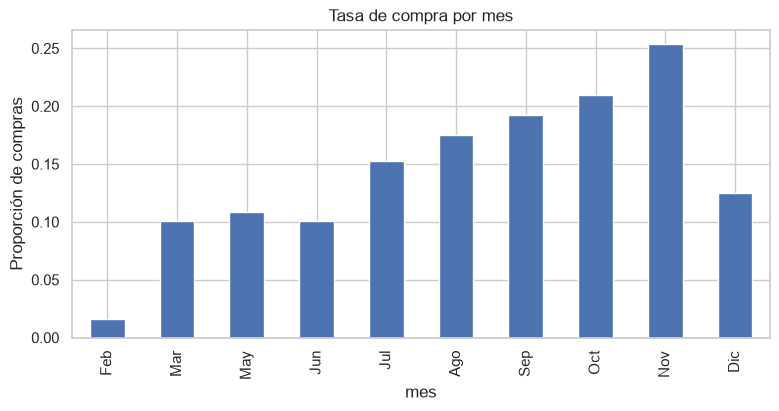

tipo_visitante
Nuevo         0.249
Otro          0.188
Recurrente    0.139
Name: compra, dtype: float64


In [9]:
orden_meses = ['Feb', 'Mar', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
tasa_mes = df.groupby('mes')['compra'].mean().reindex(orden_meses)
tasa_mes.plot(kind='bar', figsize=(9, 4), title='Tasa de compra por mes')
plt.ylabel('Proporción de compras')
plt.savefig('../docs/capturas/03_tasa_mes.png', dpi=120, bbox_inches='tight')
plt.show()

print(df.groupby('tipo_visitante')['compra'].mean().round(3))

### Matriz de correlación

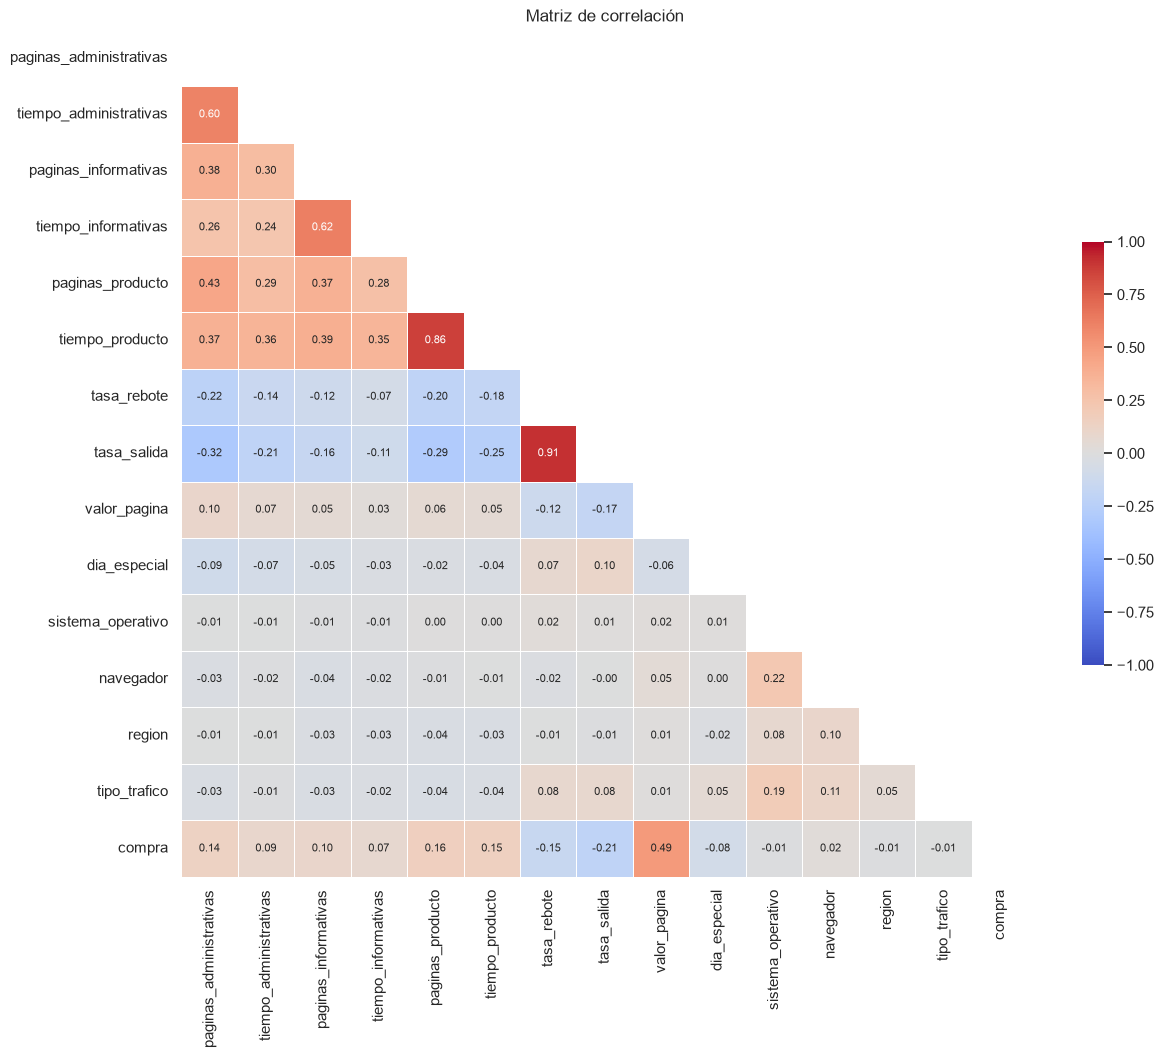

valor_pagina               0.493
paginas_producto           0.159
tiempo_producto            0.152
paginas_administrativas    0.139
paginas_informativas       0.095
tiempo_administrativas     0.094
tiempo_informativas        0.070
navegador                  0.024
tipo_trafico              -0.005
region                    -0.012
sistema_operativo         -0.015
dia_especial              -0.082
tasa_rebote               -0.151
tasa_salida               -0.207
Name: compra, dtype: float64

In [10]:
matriz_correlacion = df.select_dtypes(include='number').assign(compra=df['compra'].astype(int)).corr()
mask = np.triu(np.ones_like(matriz_correlacion, dtype=bool))
plt.figure(figsize=(14, 11))
sns.heatmap(matriz_correlacion, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={'shrink': .5}, annot_kws={'size': 8})
plt.grid(False)
plt.title('Matriz de correlación')
plt.savefig('../docs/capturas/04_correlacion.png', dpi=120, bbox_inches='tight')
plt.show()

matriz_correlacion['compra'].drop('compra').sort_values(ascending=False).round(3)

## Fase 2 · Data Engineering

### Limpieza y división 80/20

In [11]:
df = df.drop_duplicates()
print('Filas después de quitar duplicados:', df.shape[0])

df['fin_de_semana'] = df['fin_de_semana'].astype(int)
df['compra'] = df['compra'].astype(int)

X = df.drop(columns='compra')
y = df['compra']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Proporción de compras  train: %.3f  test: %.3f' % (y_train.mean(), y_test.mean()))

Filas después de quitar duplicados: 12205
Train: (9764, 17)  Test: (2441, 17)
Proporción de compras  train: 0.156  test: 0.156


### Pipeline de preprocesamiento

In [12]:
columnas_categoricas = ['mes', 'tipo_visitante']
columnas_numericas = [c for c in X.columns if c not in columnas_categoricas]

preprocesador = ColumnTransformer([
    ('num', Pipeline([
        ('imputar', SimpleImputer(strategy='median')),
        ('escalar', StandardScaler())
    ]), columnas_numericas),
    ('cat', Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), columnas_categoricas)
])

print('Numéricas:', columnas_numericas)
print('Categóricas:', columnas_categoricas)

Numéricas: ['paginas_administrativas', 'tiempo_administrativas', 'paginas_informativas', 'tiempo_informativas', 'paginas_producto', 'tiempo_producto', 'tasa_rebote', 'tasa_salida', 'valor_pagina', 'dia_especial', 'sistema_operativo', 'navegador', 'region', 'tipo_trafico', 'fin_de_semana']
Categóricas: ['mes', 'tipo_visitante']


## Fase 3 · ML Model Engineering

### Comparación de 5 modelos con validación cruzada

In [13]:
f2 = make_scorer(fbeta_score, beta=2)
metricas_cv = {'recall': 'recall', 'precision': 'precision', 'f2': f2, 'roc_auc': 'roc_auc'}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

peso_positivos = (y_train == 0).sum() / (y_train == 1).sum()
print('scale_pos_weight = %.2f' % peso_positivos)

modelos = {
    'Regresión Logística': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE),
    'Árbol de Decisión': DecisionTreeClassifier(class_weight='balanced', max_depth=6, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                            random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4,
                             scale_pos_weight=peso_positivos, eval_metric='logloss',
                             random_state=RANDOM_STATE, n_jobs=-1)
}

resultados = []
for nombre, modelo in modelos.items():
    pipe = Pipeline([('prep', preprocesador), ('modelo', modelo)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metricas_cv, n_jobs=1)
    resultados.append({'modelo': nombre, **{m: r['test_' + m].mean() for m in metricas_cv}})

tabla_modelos = pd.DataFrame(resultados).set_index('modelo').sort_values('f2', ascending=False).round(3)
tabla_modelos

scale_pos_weight = 5.40


,recall,precision,f2,roc_auc
modelo,,,,
Árbol de Decisión,0.829,0.489,0.728,0.891
XGBoost,0.776,0.579,0.726,0.925
Random Forest,0.737,0.640,0.715,0.930
Regresión Logística,0.761,0.524,0.698,0.900
KNN,0.315,0.752,0.356,0.836


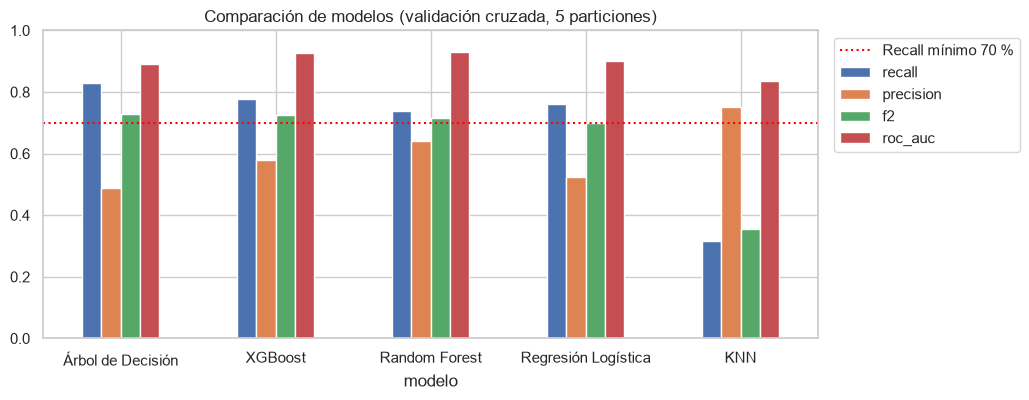

Los 2 mejores por F2: ['Árbol de Decisión', 'XGBoost']


In [14]:
tabla_modelos[['recall', 'precision', 'f2', 'roc_auc']].plot(kind='bar', figsize=(10, 4), rot=0)
plt.axhline(0.70, color='red', linestyle=':', label='Recall mínimo 70 %')
plt.title('Comparación de modelos (validación cruzada, 5 particiones)')
plt.ylim(0, 1); plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.savefig('../docs/capturas/05_comparacion_modelos.png', dpi=120, bbox_inches='tight')
plt.show()

top2 = list(tabla_modelos.index[:2])
print('Los 2 mejores por F2:', top2)

### Optimización de hiperparámetros de los 2 mejores

In [15]:
busquedas = {
    'Regresión Logística': (
        Pipeline([('prep', preprocesador),
                  ('modelo', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE))]),
        {'modelo__C': [0.01, 0.1, 0.5, 1, 5, 10]}
    ),
    'Árbol de Decisión': (
        Pipeline([('prep', preprocesador),
                  ('modelo', DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE))]),
        {'modelo__max_depth': [3, 4, 5, 6, 8, 10],
         'modelo__min_samples_leaf': [1, 5, 10, 20, 50]}
    ),
    'KNN': (
        Pipeline([('prep', preprocesador), ('modelo', KNeighborsClassifier())]),
        {'modelo__n_neighbors': [5, 11, 15, 25, 35], 'modelo__weights': ['uniform', 'distance']}
    ),
    'Random Forest': (
        Pipeline([('prep', preprocesador),
                  ('modelo', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))]),
        {'modelo__n_estimators': [200, 300, 500],
         'modelo__max_depth': [6, 8, 10, 14, None],
         'modelo__min_samples_leaf': [1, 3, 5, 10],
         'modelo__max_features': ['sqrt', 0.5]}
    ),
    'XGBoost': (
        Pipeline([('prep', preprocesador),
                  ('modelo', XGBClassifier(scale_pos_weight=peso_positivos, eval_metric='logloss',
                                           random_state=RANDOM_STATE, n_jobs=-1))]),
        {'modelo__n_estimators': [200, 300, 500],
         'modelo__max_depth': [3, 4, 5, 6],
         'modelo__learning_rate': [0.03, 0.05, 0.1],
         'modelo__subsample': [0.8, 1.0],
         'modelo__colsample_bytree': [0.7, 0.8, 1.0],
         'modelo__min_child_weight': [1, 3, 5]}
    )
}

mejores = {}
for nombre in top2:
    pipe, grilla = busquedas[nombre]
    n_combinaciones = int(np.prod([len(v) for v in grilla.values()]))
    busqueda = RandomizedSearchCV(pipe, grilla, n_iter=min(15, n_combinaciones), scoring=f2, cv=cv,
                                  random_state=RANDOM_STATE, n_jobs=1)
    busqueda.fit(X_train, y_train)
    mejores[nombre] = busqueda
    print(nombre, '-> F2 CV = %.3f' % busqueda.best_score_)
    print('   ', busqueda.best_params_)

Árbol de Decisión -> F2 CV = 0.751
    {'modelo__min_samples_leaf': 1, 'modelo__max_depth': 3}


XGBoost -> F2 CV = 0.754
    {'modelo__subsample': 1.0, 'modelo__n_estimators': 300, 'modelo__min_child_weight': 5, 'modelo__max_depth': 3, 'modelo__learning_rate': 0.03, 'modelo__colsample_bytree': 0.8}


### Modelo elegido

In [16]:
nombre_ganador = max(mejores, key=lambda n: mejores[n].best_score_)
modelo_final = mejores[nombre_ganador].best_estimator_
hiperparametros = {k.replace('modelo__', ''): v for k, v in mejores[nombre_ganador].best_params_.items()}
print('Modelo elegido:', nombre_ganador)
print(hiperparametros)

Modelo elegido: XGBoost
{'subsample': 1.0, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


## Fase 4 · Evaluation & QA

### Umbral de decisión

Umbral elegido: 0.44


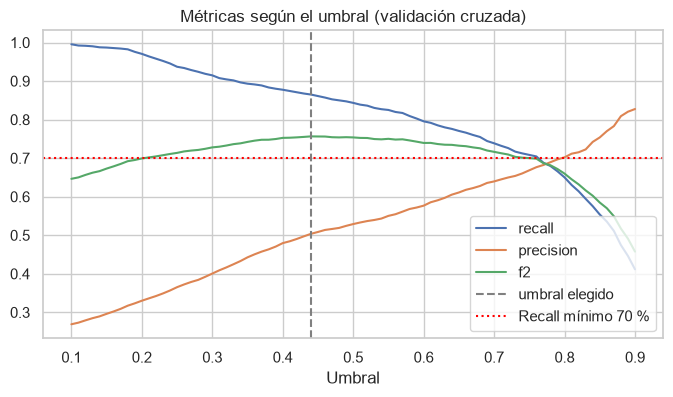

In [17]:
prob_cv = cross_val_predict(modelo_final, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

umbrales = np.arange(0.10, 0.91, 0.01)
tabla_umbral = pd.DataFrame({
    'umbral': umbrales,
    'recall': [recall_score(y_train, prob_cv >= u) for u in umbrales],
    'precision': [precision_score(y_train, prob_cv >= u, zero_division=0) for u in umbrales],
    'f2': [fbeta_score(y_train, prob_cv >= u, beta=2) for u in umbrales]
})
candidatos = tabla_umbral[tabla_umbral['recall'] >= 0.70]
umbral = float(round(candidatos.loc[candidatos['f2'].idxmax(), 'umbral'], 2))
print('Umbral elegido:', umbral)

plt.figure(figsize=(8, 4))
for m in ['recall', 'precision', 'f2']:
    plt.plot(tabla_umbral['umbral'], tabla_umbral[m], label=m)
plt.axvline(umbral, color='gray', linestyle='--', label='umbral elegido')
plt.axhline(0.70, color='red', linestyle=':', label='Recall mínimo 70 %')
plt.xlabel('Umbral'); plt.legend(); plt.title('Métricas según el umbral (validación cruzada)')
plt.savefig('../docs/capturas/06_umbral.png', dpi=120, bbox_inches='tight')
plt.show()

### Test ciego

In [18]:
modelo_final.fit(X_train, y_train)
prob_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= umbral).astype(int)

metricas_test = {
    'recall': recall_score(y_test, pred_test),
    'precision': precision_score(y_test, pred_test),
    'f1': f1_score(y_test, pred_test),
    'f2': fbeta_score(y_test, pred_test, beta=2),
    'roc_auc': roc_auc_score(y_test, prob_test)
}
for k, v in metricas_test.items():
    print('%-10s %.3f' % (k, v))
print()
print(classification_report(y_test, pred_test, target_names=['No compra', 'Compra']))
print('¿Cumple Recall >= 70 %?', 'SÍ' if metricas_test['recall'] >= 0.70 else 'NO')

recall     0.893
precision  0.506
f1         0.646
f2         0.774
roc_auc    0.939

              precision    recall  f1-score   support

   No compra       0.98      0.84      0.90      2059
      Compra       0.51      0.89      0.65       382

    accuracy                           0.85      2441
   macro avg       0.74      0.87      0.77      2441
weighted avg       0.90      0.85      0.86      2441

¿Cumple Recall >= 70 %? SÍ


### Matriz de confusión y curva ROC

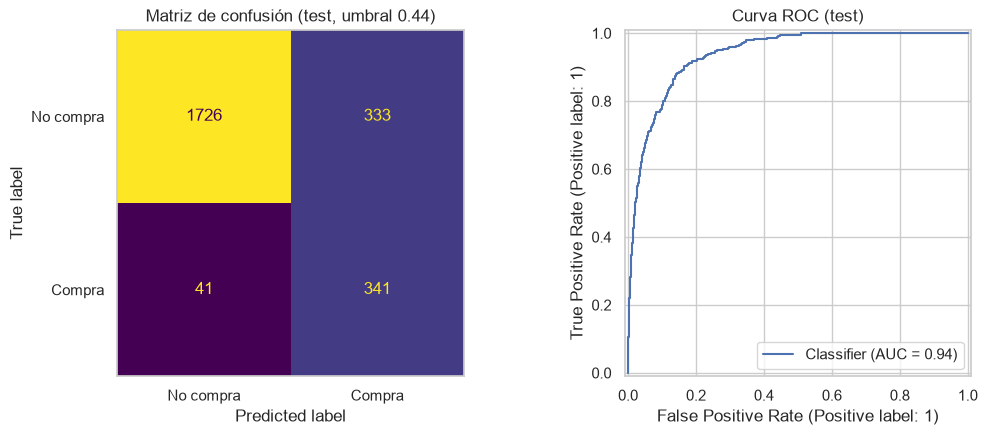

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=['No compra', 'Compra']).plot(ax=axes[0], colorbar=False)
axes[0].set_title('Matriz de confusión (test, umbral %.2f)' % umbral)
axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, prob_test, ax=axes[1])
axes[1].set_title('Curva ROC (test)')
plt.savefig('../docs/capturas/07_confusion_roc.png', dpi=120, bbox_inches='tight')
plt.show()

### Importancia de variables

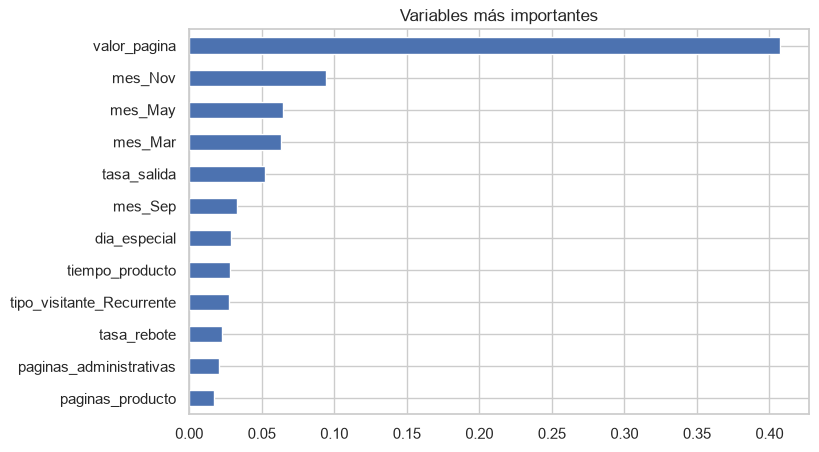

valor_pagina                 0.407
mes_Nov                      0.094
mes_May                      0.064
mes_Mar                      0.063
tasa_salida                  0.052
mes_Sep                      0.033
dia_especial                 0.029
tiempo_producto              0.028
tipo_visitante_Recurrente    0.028
tasa_rebote                  0.023
dtype: float32

In [20]:
nombres = modelo_final.named_steps['prep'].get_feature_names_out()
nombres = [n.split('__')[1] for n in nombres]
estimador = modelo_final.named_steps['modelo']
valores = estimador.feature_importances_ if hasattr(estimador, 'feature_importances_') else np.abs(estimador.coef_[0])
importancia = pd.Series(valores, index=nombres).sort_values(ascending=False)

importancia.head(12).sort_values().plot(kind='barh', figsize=(8, 5), title='Variables más importantes')
plt.savefig('../docs/capturas/08_importancia.png', dpi=120, bbox_inches='tight')
plt.show()
importancia.head(10).round(3)

### Robustez

In [21]:
continuas = ['tiempo_administrativas', 'tiempo_informativas', 'tiempo_producto',
             'tasa_rebote', 'tasa_salida', 'valor_pagina']
rng = np.random.default_rng(RANDOM_STATE)
X_ruido = X_test.copy()
for c in continuas:
    X_ruido[c] = (X_ruido[c] + rng.normal(0, 0.05 * X_test[c].std(), len(X_ruido))).clip(lower=0)

recall_ruido = recall_score(y_test, modelo_final.predict_proba(X_ruido)[:, 1] >= umbral)
print('Recall original: %.3f   Recall con ruido: %.3f   Variación: %+.3f'
      % (metricas_test['recall'], recall_ruido, recall_ruido - metricas_test['recall']))
print('¿Sigue cumpliendo Recall >= 70 % con ruido?', 'SÍ' if recall_ruido >= 0.70 else 'NO')

Recall original: 0.893   Recall con ruido: 0.942   Variación: +0.050
¿Sigue cumpliendo Recall >= 70 % con ruido? SÍ


### Sesgos

In [22]:
evaluacion = X_test.assign(real=y_test.values, pred=pred_test)
for grupo in ['tipo_visitante', 'fin_de_semana']:
    print(evaluacion[evaluacion['real'] == 1].groupby(grupo).apply(
        lambda g: pd.Series({'compras': len(g), 'recall': (g['pred'] == 1).mean()}), include_groups=False).round(3))
    print()

                compras  recall
tipo_visitante                 
Nuevo              97.0   0.897
Recurrente        285.0   0.891

               compras  recall
fin_de_semana                 
0                282.0   0.883
1                100.0   0.920



## Exportación de la configuración para el servicio de IA

In [23]:
config = {
    'algoritmo': nombre_ganador,
    'hiperparametros': hiperparametros,
    'balanceo': 'scale_pos_weight = negativos/positivos (se recalcula al reentrenar)' if nombre_ganador == 'XGBoost' else 'class_weight=balanced',
    'comparacion_cv': tabla_modelos.reset_index().to_dict(orient='records'),
    'umbral': umbral,
    'columnas_numericas': columnas_numericas,
    'columnas_categoricas': columnas_categoricas,
    'random_state': RANDOM_STATE,
    'metricas_test': {k: round(float(v), 4) for k, v in metricas_test.items()},
    'filas_entrenamiento': int(len(X_train)),
    'filas_test': int(len(X_test))
}
with open('../backend/config_modelo.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2, ensure_ascii=False, default=str)
joblib.dump(modelo_final, '../backend/models/modelo_notebook.joblib')
print(json.dumps(config, indent=2, ensure_ascii=False, default=str))

{
  "algoritmo": "XGBoost",
  "hiperparametros": {
    "subsample": 1.0,
    "n_estimators": 300,
    "min_child_weight": 5,
    "max_depth": 3,
    "learning_rate": 0.03,
    "colsample_bytree": 0.8
  },
  "balanceo": "scale_pos_weight = negativos/positivos (se recalcula al reentrenar)",
  "comparacion_cv": [
    {
      "modelo": "Árbol de Decisión",
      "recall": 0.829,
      "precision": 0.489,
      "f2": 0.728,
      "roc_auc": 0.891
    },
    {
      "modelo": "XGBoost",
      "recall": 0.776,
      "precision": 0.579,
      "f2": 0.726,
      "roc_auc": 0.925
    },
    {
      "modelo": "Random Forest",
      "recall": 0.737,
      "precision": 0.64,
      "f2": 0.715,
      "roc_auc": 0.93
    },
    {
      "modelo": "Regresión Logística",
      "recall": 0.761,
      "precision": 0.524,
      "f2": 0.698,
      "roc_auc": 0.9
    },
    {
      "modelo": "KNN",
      "recall": 0.315,
      "precision": 0.752,
      "f2": 0.356,
      "roc_auc": 0.836
    }
  ],
  "umbral